# Penn State: Play Calling and Performance by Quarter and Score

**Research question:** How does Penn State's offensive strategy and performance change by quarter and when the team is leading, tied, or trailing?

This notebook walks through the project in plain English: learn about the data source, download and inspect the original records, reshape them into a useful table, check the results, and finish with a chart and a short summary. You do not need to write code. In VS Code, choose a Python kernel and use **Run All** to run the cells from top to bottom. Each code section is introduced by an explanation of what it does.

The data download needs internet access and a personal CollegeFootballData API key. The notebook asks for the key privately if it is not already set in your environment. It does not print or save your key.

## 1. Data source and how access works

The source is [CollegeFootballData.com](https://collegefootballdata.com), a public college-football data service. We use its historical **play-by-play** endpoint: each record describes one football play, rather than only a final game score. The official API documentation is [here](https://api.collegefootballdata.com/api-docs.json).

The endpoint is named `/plays`. Its API requires a **season year and week number** for each request. We also ask for Penn State games, and the regular season. That means the notebook makes one small request per week in the seasons you choose. Empty weeks are okay; API errors are reported instead of being silently skipped.

The API requires your own bearer key. You can request one from CollegeFootballData.com. Keep it private. The next setup step reads `CFBD_API_KEY` from your environment, or asks for it with hidden input. Do not paste your key into a notebook cell, save it in the notebook, or share it.

## 2. Set up the tools and season range

The next cell loads the tools needed to send web requests, organize records into tables, and draw the one chart at the end. It also sets the season range. The default is 2021–2025; change `FIRST_SEASON` or `LAST_SEASON` if you want a different period. Each season checks up to 15 regular-season weeks, and the weekly results are cached in this notebook session so rerunning a cell does not immediately repeat requests.

If Python says that pandas or matplotlib is missing, install them in the selected environment with `python -m pip install pandas matplotlib`, then restart the notebook kernel.

In [2]:
import getpass
import json
import os
import urllib.error
import urllib.parse
import urllib.request

import matplotlib.pyplot as plt
import pandas as pd

FIRST_SEASON = 2021
LAST_SEASON = 2025
TEAM_NAME = "Penn State"
SEASON_TYPE = "regular"
WEEKS_TO_CHECK = range(1, 16)
API_BASE = "https://api.collegefootballdata.com"

API_KEY = os.environ.get("CFBD_API_KEY")
if not API_KEY:
    API_KEY = getpass.getpass("CollegeFootballData API key (input is hidden): ")
if not API_KEY.strip():
    raise ValueError("No API key was entered. Get a key from CollegeFootballData.com and run this cell again.")

weekly_cache = {}
print(f"Ready to request {TEAM_NAME} regular-season plays, {FIRST_SEASON}-{LAST_SEASON}.")
print("The key is hidden and will not be displayed.")

Ready to request Penn State regular-season plays, 2021-2025.
The key is hidden and will not be displayed.


### Download the play records

This cell requests each week for each selected season. The `/plays` API requires both year and week; Penn State and regular season are additional filters. The API key is sent in the request's authorization header, never included in the web address or printed. The small in-memory cache reuses results if you rerun this download cell during the same kernel session.

A successful week returns a list of play records. If the provider rejects the key, applies a rate limit, or cannot be reached, the cell explains the problem and stops rather than claiming the download succeeded.

In [3]:
def get_week_plays(season, week):
    cache_key = (season, week)
    if cache_key in weekly_cache:
        return weekly_cache[cache_key]

    query = urllib.parse.urlencode({
        "year": season,
        "week": week,
        "team": TEAM_NAME,
        "seasonType": SEASON_TYPE,
    })
    request = urllib.request.Request(
        f"{API_BASE}/plays?{query}",
        headers={
            "Authorization": "Bearer " + API_KEY.strip(),
            "Accept": "application/json",
        },
    )

    try:
        with urllib.request.urlopen(request, timeout=45) as response:
            result = json.loads(response.read().decode("utf-8"))
    except urllib.error.HTTPError as error:
        if error.code in (401, 403):
            message = "The API key was rejected or does not have access to this data. Check your key and account access."
        elif error.code == 429:
            message = "The API request limit was reached. Wait before trying again."
        else:
            message = f"CollegeFootballData returned HTTP {error.code} for {season}, week {week}."
        raise RuntimeError(message) from None
    except urllib.error.URLError as error:
        raise RuntimeError(f"Could not reach CollegeFootballData.com: {error.reason}") from None
    except json.JSONDecodeError:
        raise RuntimeError(f"The API response for {season}, week {week} was not valid JSON.") from None

    if not isinstance(result, list):
        raise RuntimeError(f"The API returned an unexpected response for {season}, week {week}.")
    weekly_cache[cache_key] = result
    return result


raw_records = []
total_weeks = (LAST_SEASON - FIRST_SEASON + 1) * len(WEEKS_TO_CHECK)
checked_weeks = 0
for season in range(FIRST_SEASON, LAST_SEASON + 1):
    for week in WEEKS_TO_CHECK:
        week_records = get_week_plays(season, week)
        for record in week_records:
            record_with_request_info = dict(record)
            record_with_request_info["_requested_season"] = season
            record_with_request_info["_requested_week"] = week
            raw_records.append(record_with_request_info)
        checked_weeks += 1
        if checked_weeks % 10 == 0 or checked_weeks == total_weeks:
            print(f"Checked {checked_weeks} of {total_weeks} season-weeks...")

if not raw_records:
    raise ValueError("No play records were returned. Check the season range and API access.")
print(f"Download finished: {len(raw_records):,} play records from {checked_weeks} season-weeks.")

Checked 10 of 75 season-weeks...
Checked 20 of 75 season-weeks...
Checked 30 of 75 season-weeks...
Checked 40 of 75 season-weeks...
Checked 50 of 75 season-weeks...
Checked 60 of 75 season-weeks...
Checked 70 of 75 season-weeks...
Checked 75 of 75 season-weeks...
Download finished: 10,565 play records from 75 season-weeks.


## 3. Inspect the raw data before cleaning it

The API returns JSON: a list of play records, with one dictionary (a set of named fields) per play. Fields include `gameId` (which game), `offense` and `defense` (who had the ball and who defended), `period` (quarter or overtime), `down`, `distance` (yards to the first down or goal line), `yardsGained`, `playType`, and `playText`. `offenseScore` and `defenseScore` are the scores from the offense/defense perspective **at the time of the play**, which lets us label the score situation before that play.

The API's play object does not include the request's season and week as fields, so the download cell adds `_requested_season` and `_requested_week` to each record. This cell shows a few original records and the table's dimensions/field names; we have not yet selected or summarized anything.

In [4]:
raw_plays = pd.DataFrame.from_records(raw_records)
print(f"Raw table: {raw_plays.shape[0]:,} rows and {raw_plays.shape[1]} columns")
print("Fields returned by the API plus our request labels:")
print(", ".join(raw_plays.columns.astype(str)))
print("\nThree example raw records:")
for record in raw_records[:3]:
    print(json.dumps(record, indent=2, ensure_ascii=False))

Raw table: 10,565 rows and 29 columns
Fields returned by the API plus our request labels:
gameId, driveId, id, driveNumber, playNumber, offense, offenseConference, offenseScore, defense, defenseConference, defenseScore, home, away, period, clock, offenseTimeouts, defenseTimeouts, yardline, yardsToGoal, down, distance, yardsGained, scoring, playType, playText, ppa, wallclock, _requested_season, _requested_week

Three example raw records:
{
  "gameId": 401282815,
  "driveId": "4012828151",
  "id": "401282815101849902",
  "driveNumber": 1,
  "playNumber": 1,
  "offense": "Wisconsin",
  "offenseConference": "Big Ten",
  "offenseScore": 0,
  "defense": "Penn State",
  "defenseConference": "Big Ten",
  "defenseScore": 0,
  "home": "Wisconsin",
  "away": "Penn State",
  "period": 1,
  "clock": {
    "minutes": 15,
    "seconds": 0
  },
  "offenseTimeouts": 3,
  "defenseTimeouts": 3,
  "yardline": 35,
  "yardsToGoal": 65,
  "down": 1,
  "distance": 10,
  "yardsGained": 0,
  "scoring": false,
 

## 4. Clean the plays into a simple analysis table

The raw download includes Penn State plays on offense and defense, plus non-run/pass plays such as kicks. We keep plays where **Penn State is the offense**, then classify the play as a run or pass using the API's `playType`. Sacks count as pass plays. Other play types are counted and set aside so the run/pass percentages have a clear denominator.

Each cleaned row represents one Penn State offensive run or pass. We keep the season, week, game, opponent, quarter, down, distance, yards gained, play type, and scores. Score state is calculated from the scores recorded before the play: Penn State's offense score minus the defense score. A positive margin means Penn State is leading, zero means tied, and a negative margin means trailing.

For a comparable success measure, a play must gain at least 50% of the yards-to-go on first down, 70% on second down, or the full yards-to-go on third/fourth down. “Explosive pass” below means a pass play with 15+ yards gained; it is only a proxy for a long throw, **not air yards or depth the ball traveled**. Missing fields needed for a measure stay missing rather than being treated as zero.

In [5]:
required_fields = {
    "id", "gameId", "offense", "defense", "period", "down", "distance",
    "yardsGained", "playType", "offenseScore", "defenseScore",
    "_requested_season", "_requested_week",
}
missing_fields = required_fields.difference(raw_plays.columns)
if missing_fields:
    raise ValueError("The API response is missing required fields: " + ", ".join(sorted(missing_fields)))

penn_state_offense = raw_plays.loc[
    raw_plays["offense"].astype(str).str.casefold().eq(TEAM_NAME.casefold())
].copy()
penn_state_offense["opponent"] = penn_state_offense["defense"]
penn_state_offense["play_type_text"] = penn_state_offense["playType"].fillna("").astype(str).str.casefold()
penn_state_offense["play_kind"] = "Other"
penn_state_offense.loc[penn_state_offense["play_type_text"].str.contains("rush", regex=False), "play_kind"] = "Rush"
is_pass = penn_state_offense["play_type_text"].str.contains("pass|sack", regex=True)
penn_state_offense.loc[is_pass, "play_kind"] = "Pass"

other_play_count = int(penn_state_offense["play_kind"].eq("Other").sum())
plays = penn_state_offense.loc[penn_state_offense["play_kind"].isin(["Rush", "Pass"])].copy()
plays = plays.rename(columns={
    "_requested_season": "season",
    "_requested_week": "week",
    "gameId": "game_id",
    "offenseScore": "penn_state_score_before_play",
    "defenseScore": "opponent_score_before_play",
    "period": "quarter_number",
    "distance": "yards_to_go",
    "yardsGained": "yards_gained",
    "playText": "play_description",
    "ppa": "play_value_ppa",
})

numeric_columns = [
    "season", "week", "quarter_number", "down", "yards_to_go", "yards_gained",
    "penn_state_score_before_play", "opponent_score_before_play", "play_value_ppa",
]
for column in numeric_columns:
    if column in plays.columns:
        plays[column] = pd.to_numeric(plays[column], errors="coerce")

margin = plays["penn_state_score_before_play"] - plays["opponent_score_before_play"]
plays["score_state"] = "Unknown"
plays.loc[margin.gt(0), "score_state"] = "Leading"
plays.loc[margin.eq(0), "score_state"] = "Tied"
plays.loc[margin.lt(0), "score_state"] = "Trailing"
plays["quarter"] = plays["quarter_number"].map(
    lambda value: f"Q{int(value)}" if pd.notna(value) and 1 <= value <= 4
    else f"OT{int(value) - 4}" if pd.notna(value) and value > 4
    else "Unknown"
)
plays["play_kind"] = pd.Categorical(plays["play_kind"], categories=["Rush", "Pass"])

def is_successful(row):
    yards = row["yards_gained"]
    down = row["down"]
    distance = row["yards_to_go"]
    if pd.isna(yards) or pd.isna(down) or pd.isna(distance) or down not in (1, 2, 3, 4):
        return pd.NA
    target_fraction = {1: 0.5, 2: 0.7, 3: 1.0, 4: 1.0}[int(down)]
    return bool(yards >= distance * target_fraction)

plays["success"] = plays.apply(is_successful, axis=1).astype("boolean")
known_pass_yards = plays["play_kind"].eq("Pass") & plays["yards_gained"].notna()
plays["explosive_pass_15_plus"] = pd.Series(pd.NA, index=plays.index, dtype="boolean")
plays.loc[known_pass_yards, "explosive_pass_15_plus"] = plays.loc[known_pass_yards, "yards_gained"].ge(15)

display_columns = [
    "season", "week", "game_id", "id", "opponent", "quarter", "score_state",
    "penn_state_score_before_play", "opponent_score_before_play", "down",
    "yards_to_go", "play_kind", "yards_gained", "success",
    "explosive_pass_15_plus", "play_value_ppa", "play_description",
]
display_columns = [column for column in display_columns if column in plays.columns]
print(f"Penn State offensive run/pass plays kept: {len(plays):,}")
print(f"Penn State offensive plays set aside as other types: {other_play_count:,}")
display(plays[display_columns].head(12))

Penn State offensive run/pass plays kept: 4,084
Penn State offensive plays set aside as other types: 1,286


,season,week,game_id,id,opponent,quarter,score_state,penn_state_score_before_play,opponent_score_before_play,down,yards_to_go,play_kind,yards_gained,success,explosive_pass_15_plus,play_value_ppa,play_description
3,2021,1,401282815,401282815101859901,Wisconsin,Q1,Tied,0,0,3,6,Pass,-7,False,False,-0.494982,Sean Clifford sacked by Jack Sanborn for a los...
4,2021,1,401282815,401282815101857901,Wisconsin,Q1,Tied,0,0,2,11,Pass,10,True,False,0.778455,Sean Clifford pass complete to Jahan Dotson fo...
5,2021,1,401282815,401282815101854401,Wisconsin,Q1,Tied,0,0,1,10,Rush,-1,False,<NA>,-0.801489,Noah Cain run for a loss of 1 yard to the PnSt 24
13,2021,1,401282815,401282815101914901,Wisconsin,Q1,Tied,0,0,2,8,Pass,0,False,False,-0.970268,Sean Clifford pass incomplete to Noah Cain
14,2021,1,401282815,401282815101916201,Wisconsin,Q1,Tied,0,0,3,8,Rush,4,False,<NA>,-0.163001,Noah Cain run for 4 yds to the Wisc 34
15,2021,1,401282815,401282815101899501,Wisconsin,Q1,Tied,0,0,1,10,Pass,1,False,False,-0.833418,Sean Clifford pass complete to KeAndre Lambert...
16,2021,1,401282815,401282815101906201,Wisconsin,Q1,Tied,0,0,2,9,Pass,0,False,False,-0.683929,Sean Clifford pass incomplete to Jahan Dotson
17,2021,1,401282815,401282815101914001,Wisconsin,Q1,Tied,0,0,1,10,Pass,2,False,False,-0.454930,Sean Clifford pass complete to Jahan Dotson fo...
18,2021,1,401282815,401282815101917301,Wisconsin,Q1,Tied,0,0,4,4,Pass,0,False,False,-3.885983,Sean Clifford pass incomplete to KeAndre Lambe...
19,2021,1,401282815,401282815101907901,Wisconsin,Q1,Tied,0,0,3,9,Pass,24,True,True,3.571014,Sean Clifford pass complete to Parker Washingt...


## 5. Check that the cleaned data makes sense

Before interpreting the numbers, we check for duplicate play IDs within a game, confirm every retained row is a Penn State offensive run or pass, review the seasons and quarters represented, and look for missing values in fields used for analysis. We also show whether scores are nonnegative and flag yard gains outside the usual -100-to-100 range for review.

These are transparent checks, not a claim that every provider record is perfect. A missing value is reported, not silently replaced. Some missing fields can be normal for particular records, and unusual values are flagged for human inspection rather than automatically deleted.

In [6]:
duplicate_plays = int(plays.duplicated(subset=["game_id", "id"]).sum())
assert duplicate_plays == 0, f"Found {duplicate_plays} duplicate play IDs within games. Review the raw records."
assert plays["offense"].astype(str).str.casefold().eq(TEAM_NAME.casefold()).all(), "A retained play is not Penn State offense."
assert plays["play_kind"].isin(["Rush", "Pass"]).all(), "A retained row is not classified as run or pass."

score_columns = ["penn_state_score_before_play", "opponent_score_before_play"]
scores_nonnegative = plays[score_columns].ge(0).all(axis=1)
yards_outside_expected_range = plays["yards_gained"].notna() & ~plays["yards_gained"].between(-100, 100)
missingness = plays[["quarter_number", "down", "yards_to_go", "yards_gained", *score_columns]].isna().sum()

print("Duplicate (game, play ID) pairs:", duplicate_plays)
print("All retained rows are Penn State offense and run/pass plays: yes")
print("Rows with nonnegative pre-play scores:", f"{int(scores_nonnegative.sum()):,} of {len(plays):,}")
print("Yard gains outside -100 to 100 (review these):", int(yards_outside_expected_range.sum()))
print("Missing values in analysis fields:")
display(missingness.rename("missing rows").to_frame())
print("Seasons present:", sorted(plays["season"].dropna().astype(int).unique().tolist()))
print("Periods present:", sorted(plays["quarter_number"].dropna().astype(int).unique().tolist()))
print("Checks passed: no duplicate IDs and retained rows have the expected team/play types.")

Duplicate (game, play ID) pairs: 0
All retained rows are Penn State offense and run/pass plays: yes
Rows with nonnegative pre-play scores: 4,084 of 4,084
Yard gains outside -100 to 100 (review these): 0
Missing values in analysis fields:


,missing rows
quarter_number,0
down,0
yards_to_go,0
yards_gained,0
penn_state_score_before_play,0
opponent_score_before_play,0


Seasons present: [2021, 2022, 2023, 2024, 2025]
Periods present: [1, 2, 3, 4, 5, 6]
Checks passed: no duplicate IDs and retained rows have the expected team/play types.


## 6. Compare performance and strategy by quarter and score state

This table combines the two parts of the question. For each quarter and whether Penn State was leading, tied, or trailing **before the snap**, it shows the number of Penn State run/pass plays, run and pass share, average yards per play (and by run/pass), success rate, and the percentage of passes gaining 15+ yards. Samples with very few plays should be treated cautiously.

The final chart is one picture of offensive strategy: Penn State's run share across the four quarters, with a separate line for each pre-play score state. The number shown at each point is the number of run/pass plays in that group. The companion table provides the performance measures that the chart does not show.

In [7]:
regular_quarter_plays = plays.loc[plays["quarter"].isin(["Q1", "Q2", "Q3", "Q4"])].copy()
regular_quarter_plays["is_rush"] = regular_quarter_plays["play_kind"].eq("Rush")
regular_quarter_plays["is_pass"] = regular_quarter_plays["play_kind"].eq("Pass")
regular_quarter_plays["rush_yards"] = regular_quarter_plays["yards_gained"].where(regular_quarter_plays["is_rush"])
regular_quarter_plays["pass_yards"] = regular_quarter_plays["yards_gained"].where(regular_quarter_plays["is_pass"])

summary = (
    regular_quarter_plays.groupby(["quarter", "score_state"], observed=True, sort=False)
    .agg(
        plays=("id", "count"),
        rush_plays=("is_rush", "sum"),
        pass_plays=("is_pass", "sum"),
        average_yards_per_play=("yards_gained", "mean"),
        average_rush_yards=("rush_yards", "mean"),
        average_pass_yards=("pass_yards", "mean"),
        success_rate=("success", "mean"),
        explosive_pass_rate=("explosive_pass_15_plus", "mean"),
    )
    .reset_index()
)
summary["rush_share"] = summary["rush_plays"] / summary["plays"]
summary["pass_share"] = summary["pass_plays"] / summary["plays"]
summary["quarter"] = pd.Categorical(summary["quarter"], categories=["Q1", "Q2", "Q3", "Q4"], ordered=True)
summary["score_state"] = pd.Categorical(summary["score_state"], categories=["Leading", "Tied", "Trailing"], ordered=True)
summary = summary.sort_values(["quarter", "score_state"]).reset_index(drop=True)

percent_columns = ["rush_share", "pass_share", "success_rate", "explosive_pass_rate"]
summary_display = summary.copy()
for column in percent_columns:
    summary_display[column] = summary_display[column].map(lambda value: f"{value:.1%}" if pd.notna(value) else "Not available")
for column in ["average_yards_per_play", "average_rush_yards", "average_pass_yards"]:
    summary_display[column] = summary_display[column].map(lambda value: f"{value:.1f}" if pd.notna(value) else "Not available")
display(summary_display)
print("Overtime plays are retained in the cleaned play table but excluded from this four-quarter comparison.")

,quarter,score_state,plays,rush_plays,pass_plays,average_yards_per_play,average_rush_yards,average_pass_yards,success_rate,explosive_pass_rate,rush_share,pass_share
0,Q1,Leading,200,98,102,7.8,6.1,9.5,56.5%,19.6%,49.0%,51.0%
1,Q1,Tied,522,293,229,5.2,4.7,6.0,44.1%,13.5%,56.1%,43.9%
2,Q1,Trailing,228,104,124,6.2,4.6,7.5,44.7%,25.0%,45.6%,54.4%
3,Q2,Leading,675,308,367,6.3,4.9,7.5,47.6%,18.0%,45.6%,54.4%
4,Q2,Tied,134,62,72,4.9,4.3,5.4,43.3%,18.1%,46.3%,53.7%
5,Q2,Trailing,316,163,153,6.3,4.6,8.0,44.9%,21.6%,51.6%,48.4%
6,Q3,Leading,735,416,319,6.6,5.9,7.5,49.3%,16.0%,56.6%,43.4%
7,Q3,Tied,45,24,21,5.3,3.2,7.6,44.4%,14.3%,53.3%,46.7%
8,Q3,Trailing,225,93,132,5.7,5.1,6.2,47.1%,16.7%,41.3%,58.7%
9,Q4,Leading,649,437,212,6.0,5.3,7.3,45.0%,18.9%,67.3%,32.7%


Overtime plays are retained in the cleaned play table but excluded from this four-quarter comparison.


### Draw the one chart

This cell draws a single line chart from the summary table. Each line represents a score state and each point a quarter. Higher run share means a greater share of run plays among Penn State's classified run/pass plays in that group. Point labels give the number of plays behind each estimate; use those counts when judging how much to trust a difference.

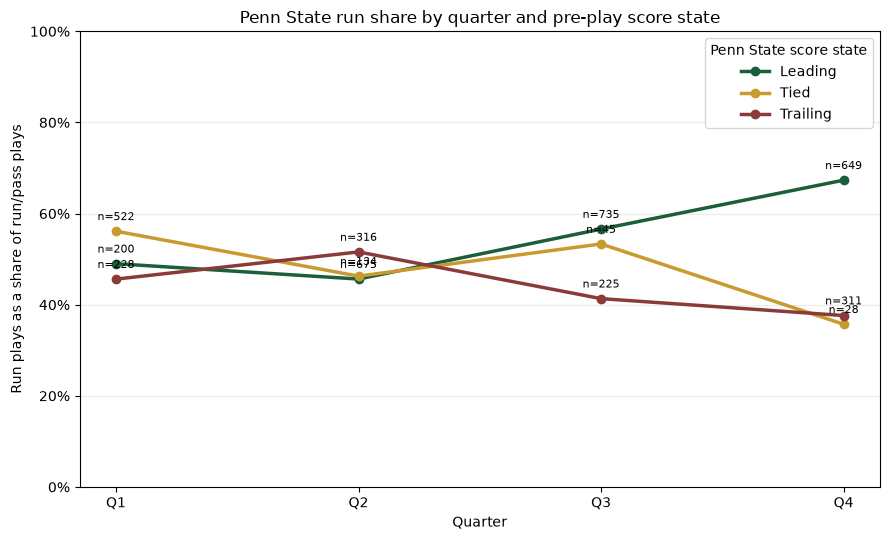

In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
colors = {"Leading": "#1b5e3b", "Tied": "#c99a2e", "Trailing": "#8b3a3a"}
quarter_order = ["Q1", "Q2", "Q3", "Q4"]
for state in ["Leading", "Tied", "Trailing"]:
    state_data = summary.loc[summary["score_state"].astype(str).eq(state)].copy()
    state_data["quarter"] = state_data["quarter"].astype(str)
    state_data = state_data.set_index("quarter").reindex(quarter_order).reset_index()
    if state_data["rush_share"].notna().any():
        ax.plot(
            state_data["quarter"], state_data["rush_share"],
            marker="o", linewidth=2.5, label=state, color=colors[state],
        )
        for _, row in state_data.dropna(subset=["rush_share"]).iterrows():
            ax.annotate(
                f"n={int(row['plays'])}",
                (row["quarter"], row["rush_share"]),
                textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8,
            )

ax.set_title("Penn State run share by quarter and pre-play score state")
ax.set_xlabel("Quarter")
ax.set_ylabel("Run plays as a share of run/pass plays")
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda value, _: f"{value:.0%}"))
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Penn State score state")
fig.tight_layout()
plt.show()

## 7. Short summary of the full process and what the data says

The final cell automatically describes what this notebook downloaded, how it defined the comparison groups, and the most/least run-heavy quarter/score-state groups. It reports performance extremes only for groups with at least 20 plays, so a handful of plays cannot dominate the takeaway. If a group is missing or too small, the notebook says so rather than inventing a conclusion.

Read this as a descriptive comparison, not proof of cause. The score itself can affect what a team chooses to do, the opponent and clock also matter, and plays while ahead may not be comparable to plays while behind. The source's 15-yard pass-gain proxy measures yards gained, not how far the ball traveled through the air.

In [ ]:
games_count = int(plays["game_id"].nunique())
run_pass_count = len(plays)
analysis_period = f"{FIRST_SEASON}-{LAST_SEASON}"
print(
    f"Process: downloaded Penn State regular-season play-by-play from "
    f"CollegeFootballData.com for {analysis_period}, inspected the original "
    f"JSON records, kept Penn State offensive run/pass plays, checked IDs "
    f"and key fields, and compared the four regulation quarters by the "
    f"score before each play. The cleaned table contains {run_pass_count:,} "
    f"run/pass plays from {games_count:,} games; {other_play_count:,} other "
    f"Penn State offensive play types were set aside."
)

enough_plays = summary.loc[summary["plays"].ge(20)].dropna(subset=["rush_share"])
if enough_plays.empty:
    print("Takeaway: there are not yet 20 plays in any quarter/score-state groups, so a stable strategy comparison is not available.")
else:
    most_run_heavy = enough_plays.loc[enough_plays["rush_share"].idxmax()]
    least_run_heavy = enough_plays.loc[enough_plays["rush_share"].idxmin()]
    print(
        f"Strategy: among groups with at least 20 plays, the highest run "
        f"share was {most_run_heavy['rush_share']:.1%} in "
        f"{most_run_heavy['quarter']} while {str(most_run_heavy['score_state']).lower()} "
        f"(n={int(most_run_heavy['plays'])}); the lowest was "
        f"{least_run_heavy['rush_share']:.1%} in {least_run_heavy['quarter']} "
        f"while {str(least_run_heavy['score_state']).lower()} "
        f"(n={int(least_run_heavy['plays'])})."
    )

performance_groups = enough_plays.dropna(subset=["average_yards_per_play"])
if performance_groups.empty:
    print("Performance: average yards per play could not be compared in groups with at least 20 plays.")
else:
    best_yards = performance_groups.loc[performance_groups["average_yards_per_play"].idxmax()]
    lowest_yards = performance_groups.loc[performance_groups["average_yards_per_play"].idxmin()]
    print(
        f"Performance: average yards per play ranged from "
        f"{lowest_yards['average_yards_per_play']:.1f} in "
        f"{lowest_yards['quarter']} while {str(lowest_yards['score_state']).lower()} "
        f"to {best_yards['average_yards_per_play']:.1f} in "
        f"{best_yards['quarter']} while {str(best_yards['score_state']).lower()} "
        f"among groups with at least 20 plays."
    )

print("Caution: these patterns describe what happened; they do not prove why the coaches chose a play or that the score caused the strategy change.")

## Save the cleaned plays to TiDB

This optional step sends the cleaned `plays` rows to your TiDB Cloud database over a TLS connection with certificate verification. It creates a separate project database named `penn_state_analytics` and a table named `penn_state_plays`; it does not write into the `sys` system database. The database password is read from the local `.env` file and is never displayed.

For safety, the cell checks first and stops if that table already exists. It will not overwrite existing data or append duplicates. Run it after the download and cleaning steps have completed.

In [ ]:
from pathlib import Path
import re
import certifi
import mysql.connector

if "plays" not in globals() or not isinstance(plays, pd.DataFrame) or plays.empty:
    raise RuntimeError("The cleaned plays table is not available. Run the notebook download and cleaning cells first.")

password = None
for env_line in (Path.cwd() / ".env").read_text(encoding="utf-8").splitlines():
    match = re.match(r"^\s*database[-_ ]password\s*[:=]\s*(.*?)\s*$", env_line, flags=re.IGNORECASE)
    if match:
        password = match.group(1).strip().strip("\"'")
        break
if not password:
    raise RuntimeError("No database-password entry was found in the project .env file.")

database_name = "penn_state_analytics"
table_name = "penn_state_plays"
upload_columns = [
    "season", "week", "game_id", "id", "opponent", "quarter", "score_state",
    "penn_state_score_before_play", "opponent_score_before_play", "down",
    "yards_to_go", "play_kind", "yards_gained", "success",
    "explosive_pass_15_plus", "play_value_ppa", "play_description",
]
missing_upload_columns = set(upload_columns).difference(plays.columns)
if missing_upload_columns:
    raise ValueError("The cleaned table is missing upload fields: " + ", ".join(sorted(missing_upload_columns)))

upload_data = plays[upload_columns].copy()
for text_column in ["quarter", "score_state", "play_kind"]:
    upload_data[text_column] = upload_data[text_column].astype("string")

connection = None
cursor = None
try:
    connection = mysql.connector.connect(
        host="gateway01.us-east-1.prod.aws.tidbcloud.com",
        port=4000,
        user="3eB6ydhjxG6RLCv.root",
        password=password,
        database="sys",
        connection_timeout=15,
        ssl_ca=certifi.where(),
        ssl_verify_cert=True,
        ssl_verify_identity=True,
    )
    cursor = connection.cursor()
    cursor.execute(
        "SELECT COUNT(*) FROM information_schema.tables "
        "WHERE table_schema = %s AND table_name = %s",
        (database_name, table_name),
    )
    if cursor.fetchone()[0]:
        raise RuntimeError(
            f"{database_name}.{table_name} already exists. No rows were written; "
            "inspect that table before deciding whether to replace it."
        )

    cursor.execute(
        f"CREATE DATABASE IF NOT EXISTS `{database_name}` "
        "CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci"
    )
    cursor.execute(f"USE `{database_name}`")
    cursor.execute(
        f"CREATE TABLE `{table_name}` ("
        "season SMALLINT NOT NULL, "
        "week SMALLINT NULL, "
        "game_id BIGINT NOT NULL, "
        "id VARCHAR(128) NOT NULL, "
        "opponent VARCHAR(128) NULL, "
        "quarter VARCHAR(8) NULL, "
        "score_state VARCHAR(16) NULL, "
        "penn_state_score_before_play INT NULL, "
        "opponent_score_before_play INT NULL, "
        "down TINYINT NULL, "
        "yards_to_go SMALLINT NULL, "
        "play_kind VARCHAR(8) NULL, "
        "yards_gained SMALLINT NULL, "
        "success BOOLEAN NULL, "
        "explosive_pass_15_plus BOOLEAN NULL, "
        "play_value_ppa DOUBLE NULL, "
        "play_description TEXT NULL, "
        "PRIMARY KEY (game_id, id)"
        ") CHARACTER SET utf8mb4 COLLATE utf8mb4_unicode_ci"
    )

    insert_sql = (
        f"INSERT INTO `{table_name}` ({', '.join(f'`{col}`' for col in upload_columns)}) "
        f"VALUES ({', '.join(['%s'] * len(upload_columns))})"
    )
    rows = []
    for values in upload_data.itertuples(index=False, name=None):
        row_values = []
        for value in values:
            if pd.isna(value):
                row_values.append(None)
            elif hasattr(value, "item"):
                row_values.append(value.item())
            else:
                row_values.append(value)
        rows.append(tuple(row_values))

    connection.start_transaction()
    batch_size = 500
    for offset in range(0, len(rows), batch_size):
        cursor.executemany(insert_sql, rows[offset:offset + batch_size])
    connection.commit()

    cursor.execute(f"SELECT COUNT(*) FROM `{table_name}`")
    stored_count = int(cursor.fetchone()[0])
    if stored_count != len(upload_data):
        raise RuntimeError(
            f"Upload verification failed: expected {len(upload_data):,} rows, "
            f"but the table contains {stored_count:,}."
        )
    print(
        f"Upload verified: {stored_count:,} cleaned plays are in "
        f"{database_name}.{table_name}."
    )
except mysql.connector.Error as error:
    if connection is not None and connection.in_transaction:
        connection.rollback()
    raise RuntimeError(
        "TiDB upload failed. Check database permissions and network access "
        f"(connector code {getattr(error, 'errno', 'unknown')}, "
        f"SQL state {getattr(error, 'sqlstate', 'unknown')})."
    ) from None
finally:
    if cursor is not None:
        cursor.close()
    if connection is not None and connection.is_connected():
        connection.close()
    password = None